# Machine Learning - Assignment 2
## MNIST Dataset Analysis and Classification Model Training

**Done by:** Osama Al-Asadi

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
import joblib

Matplotlib is building the font cache; this may take a moment.


In [5]:
train = pd.read_csv('MNIST\mnist_train.csv')
test = pd.read_csv('MNIST\mnist_test.csv')

In [6]:
test.shape

(10000, 785)

In [7]:
df = pd.concat([train, test], ignore_index=False)
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
df['label'].value_counts()

label
1    7877
7    7293
3    7141
2    6990
9    6958
0    6903
6    6876
8    6825
4    6824
5    6313
Name: count, dtype: int64

In [10]:
df.isnull().sum().sum()

np.int64(0)

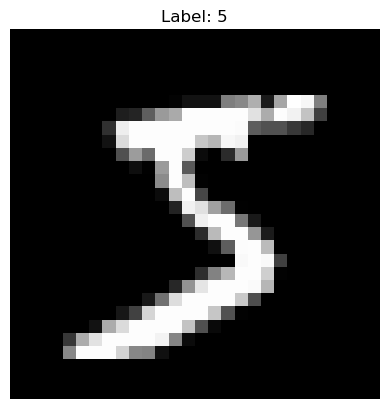

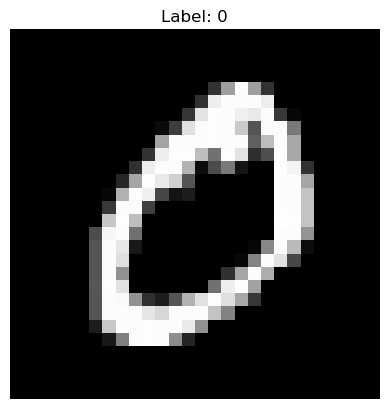

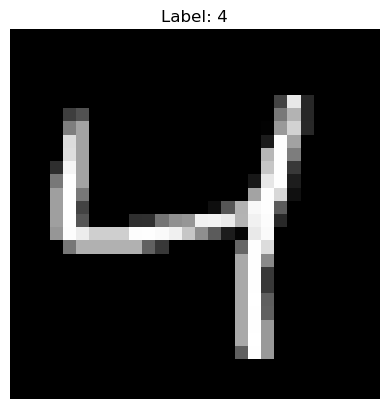

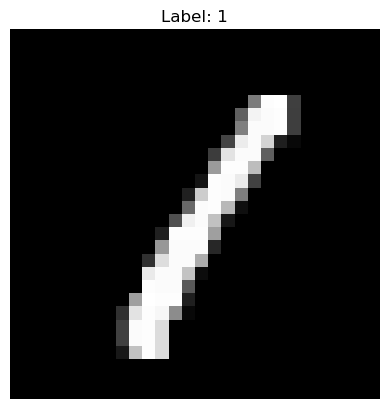

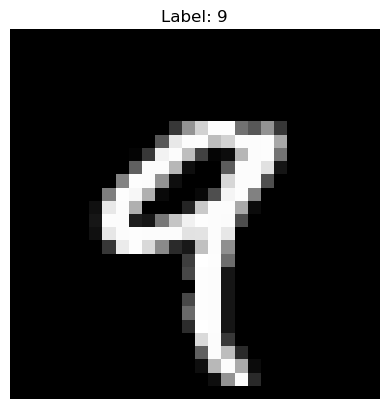

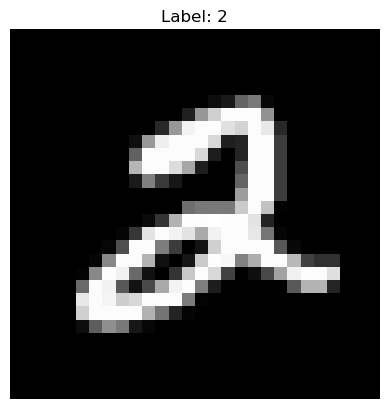

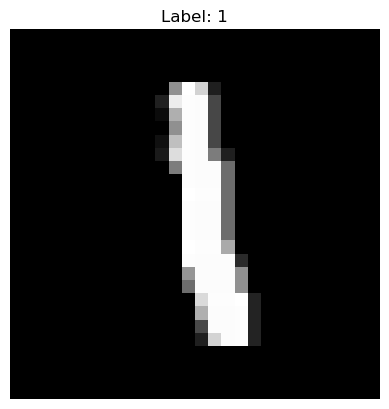

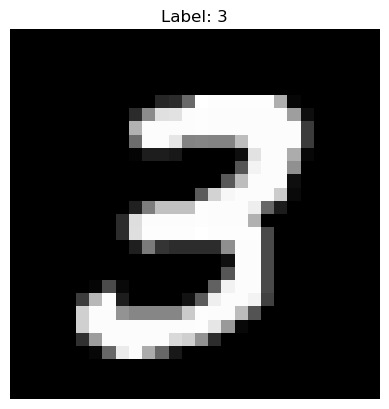

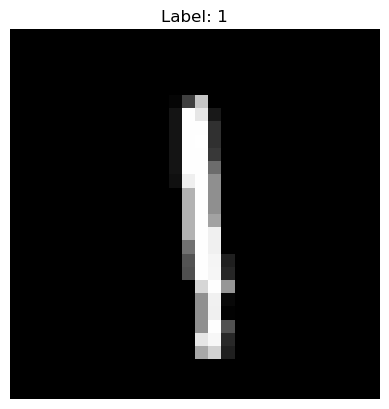

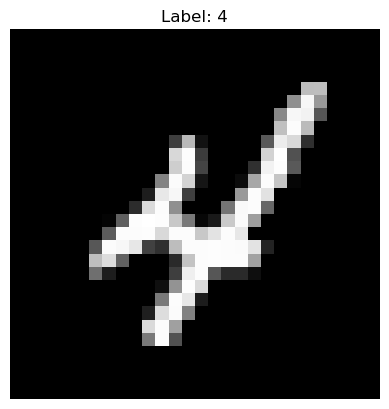

In [14]:
def display_image(index):
    pixels = df.iloc[index, 1:].values.reshape(28, 28)
    label = df.iloc[index, 0]
    plt.imshow(pixels, cmap='gray')
    plt.title(f"Label: {label}")
    plt.axis('off')
    plt.show()

for i in range(10):
    display_image(i)

### Training
#### XGBoost

In [15]:
X = df.drop('label', axis=1)
y = df['label']

In [16]:
# Normalize the pixel values
X = X / 255.0

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
xgb_model = xgb.XGBClassifier(
    objective='multi:softprob', 
    num_class=10,
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1, num_class=10, ...)

In [21]:
y_pred = xgb_model.predict(X_test)

In [22]:
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {accuracy * 100:.2f}%")


Accuracy: 97.87%


In [23]:

conf_mat = confusion_matrix(y_test, y_pred)


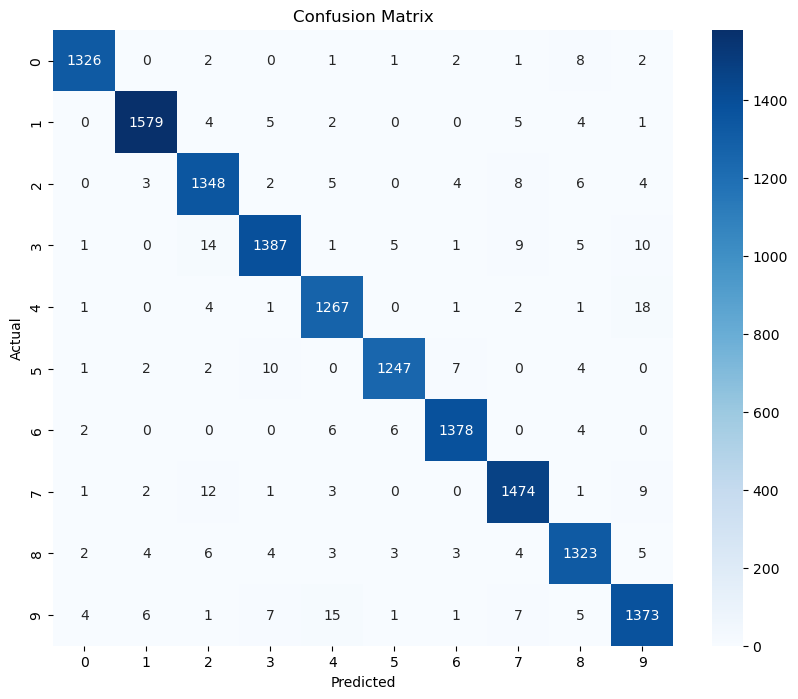

In [24]:
conf_mat = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig("confusion_matrix.png")

In [25]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1343
           1       0.99      0.99      0.99      1600
           2       0.97      0.98      0.97      1380
           3       0.98      0.97      0.97      1433
           4       0.97      0.98      0.98      1295
           5       0.99      0.98      0.98      1273
           6       0.99      0.99      0.99      1396
           7       0.98      0.98      0.98      1503
           8       0.97      0.97      0.97      1357
           9       0.97      0.97      0.97      1420

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000



In [28]:
joblib.dump(xgb_model, 'models/xgboost_MNIST_model.pkl')
print("XGBoost model saved as xgboost_MNIST_model.pkl")

XGBoost model saved as xgboost_MNIST_model.pkl


#### LightGBM

In [29]:
print("\n--- Training LightGBM Model ---")
lgbm_model = lgb.LGBMClassifier(
    objective='multiclass',
    num_class=10,
    n_jobs=-1,
    random_state=42
    )
    
lgbm_model.fit(X_train, y_train)


--- Training LightGBM Model ---
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.532994 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 108666
[LightGBM] [Info] Number of data points in the train set: 56000, number of used features: 626
[LightGBM] [Info] Start training from score -2.309754
[LightGBM] [Info] Start training from score -2.188460
[LightGBM] [Info] Start training from score -2.300801
[LightGBM] [Info] Start training from score -2.283483
[LightGBM] [Info] Start training from score -2.315345
[LightGBM] [Info] Start training from score -2.407946
[LightGBM] [Info] Start training from score -2.324247
[LightGBM] [Info] Start training from score -2.269219
[LightGBM] [Info] Start training from score -2.326439
[LightGBM] [Info] Start training from score -2.313718


LGBMClassifier(n_jobs=-1, num_class=10, objective='multiclass', random_state=42)

In [30]:
# Make predictions and evaluate
y_pred_lgbm = lgbm_model.predict(X_test)
print(f"LightGBM Accuracy: {accuracy_score(y_test, y_pred_lgbm) * 100:.2f}%")

LightGBM Accuracy: 97.59%


In [31]:
print("\nLightGBM Classification Report:")
print(classification_report(y_test, y_pred_lgbm))


LightGBM Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1343
           1       0.99      0.98      0.99      1600
           2       0.96      0.97      0.97      1380
           3       0.97      0.96      0.97      1433
           4       0.97      0.98      0.98      1295
           5       0.98      0.98      0.98      1273
           6       0.99      0.99      0.99      1396
           7       0.97      0.98      0.98      1503
           8       0.97      0.97      0.97      1357
           9       0.96      0.96      0.96      1420

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000



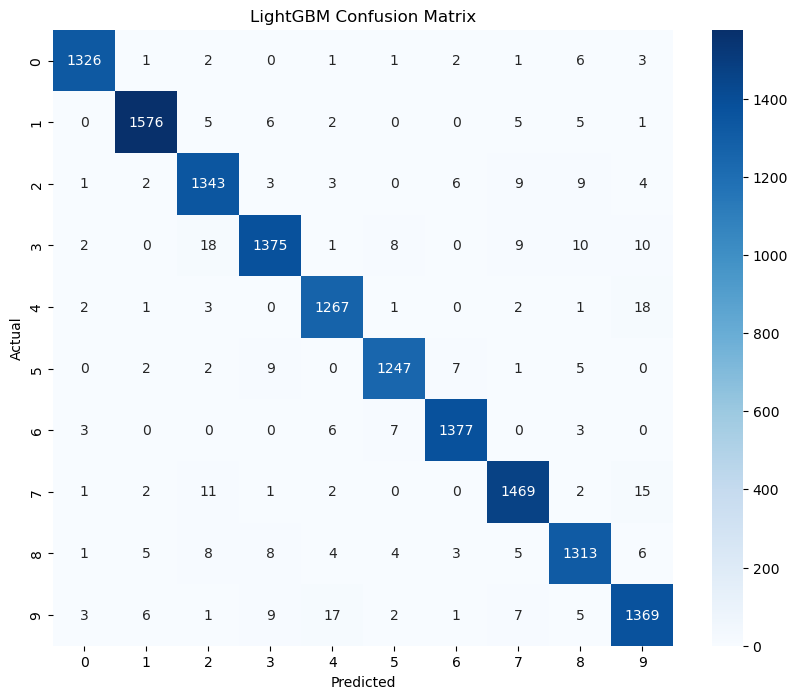

In [32]:
conf_mat_lgbm = confusion_matrix(y_test, y_pred_lgbm)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat_lgbm, annot=True, fmt='d', cmap='Blues')
plt.title('LightGBM Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig("confusion_matrix_lightgbm.png")
plt.show()

In [33]:
joblib.dump(lgbm_model, 'models/lightgbm_MNIST_model.pkl')
print("LightGBM model saved as lightgbm_MNIST_model.pkl")

LightGBM model saved as lightgbm_MNIST_model.pkl


#### Random Forest

In [34]:
print("\n--- Training Random Forest Model ---")
rf_model = RandomForestClassifier(
    n_estimators=150, 
    n_jobs=-1, 
    random_state=42)
    
rf_model.fit(X_train, y_train)


--- Training Random Forest Model ---


RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42)

In [35]:
# Make predictions and evaluate
y_pred_rf = rf_model.predict(X_test)
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%")

Random Forest Accuracy: 96.75%


In [36]:
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1343
           1       0.98      0.98      0.98      1600
           2       0.95      0.97      0.96      1380
           3       0.96      0.95      0.95      1433
           4       0.96      0.97      0.96      1295
           5       0.97      0.96      0.97      1273
           6       0.98      0.98      0.98      1396
           7       0.97      0.97      0.97      1503
           8       0.96      0.96      0.96      1357
           9       0.96      0.94      0.95      1420

    accuracy                           0.97     14000
   macro avg       0.97      0.97      0.97     14000
weighted avg       0.97      0.97      0.97     14000



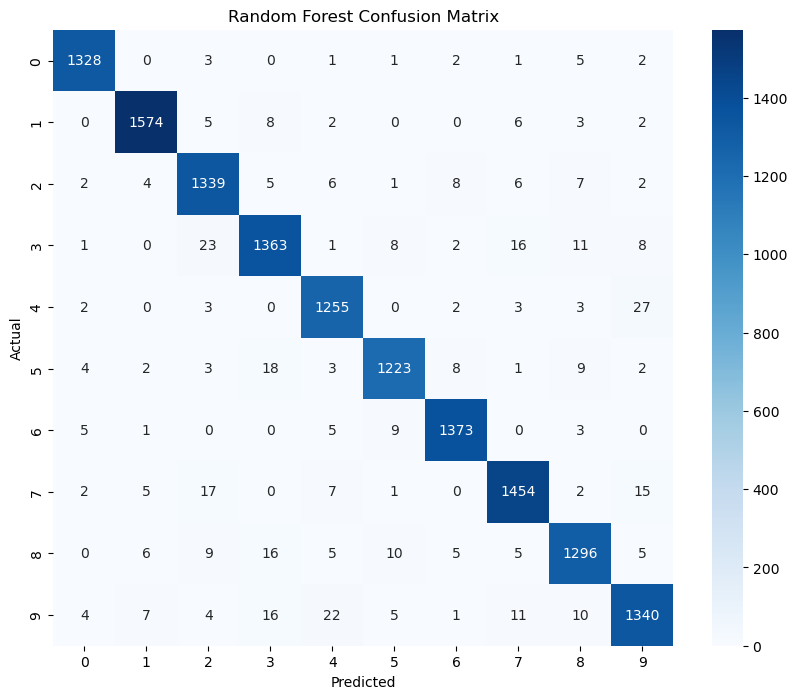

In [37]:
conf_mat_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat_rf, annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig("confusion_matrix_randomforest.png")
plt.show()

In [38]:
joblib.dump(rf_model, 'models/random_forest_MNIST_model.pkl')
print("Random Forest model saved as random_forest_MNIST_model.pkl")

Random Forest model saved as random_forest_MNIST_model.pkl
